# Where a coding-algorithm ban takes effect in an LLM

Artifact `art_8_ULPE8jJQc_` (experiment 8) is a causal **route test** for prompt-level algorithm bans in **Qwen/Qwen3-8B** (bf16, thinking off, Hub revision `b968826d`). It uses two path-search coding tasks from iteration 1's canonical suite:

- **T1** grid path `solve(grid, start, goal)`: the prompt says *"Do not use breadth-first search (BFS) for this task."*
- **T2** weighted shortest path `solve(n, edges, s, t)`: the prompt says *"Do not use Dijkstra's algorithm for this task."*

**Question.** When the model obeys a ban, where is the ban read? There are two candidate routes:

- **Direct route**: each generated token attends back to the ban sentence itself.
- **Prompt route**: the ban is already folded into the hidden states of the task-specification tokens, and of the last prompt position R, before generation starts.

**Design.** Each of 5 frozen ban templates (W1-W5) has a *neutral twin* of exactly the same token length. The twin prohibits irrelevant nouns in the same frame ("Do not use man, the house and the baby for this task."). From `Task:` onward the token ids are identical, so the KV caches of the two prompts can be **spliced position by position**:

| arm | KV of the condition span `[0, p1)` | KV of task spec + R `[p1, P)` | R logits |
|---|---|---|---|
| **a** full ban | ban | ban | ban |
| **b** neutral twin (baseline) | neutral | neutral | neutral |
| **c** PROMPT ROUTE | neutral | ban | ban |
| **d** DIRECT ROUTE | ban | neutral | neutral |

Further arms:

- **e** R-only and **f** task-spec-only;
- **pl**, a placebo splice of two neutral nouns;
- condition-span attention knockouts **K0** (all generated tokens), **K1** (first 16) and **K2** (after 16);
- layer bands **B1/B2/B3** (layers 0-11, 12-23, 24-35);
- **K0b**, the K0 knockout applied to the neutral prompt;
- the *mention* twin ("You could use BFS for this task.").

**Primary readout.** The readout and decision rule were pre-registered: the rule was sha256-committed before any arm was scored. The readout is the FRLP drop $D_X(\text{arm}) = L_X(\text{arm}) - L_X(b)$ of the banned algorithm X, an importance-weighted log-likelihood. It is measured over 30 self-written, name-scrubbed programs of X, teacher-forced on each arm's cache. The route fractions are $F_\text{prompt} = D(c)/D(a)$ and $F_\text{direct} = D(d)/D(a)$.

**Reported result:** pooled $F_\text{prompt}$ = 0.85 [0.61, 1.20] and $F_\text{direct}$ = 0.00 [-0.08, 0.12]. The ban is carried by the **prompt route**, and this holds in both tasks (ROBUST).

### What this notebook runs

The model stages of `method.py` (s2, s4, s5, s6, s7) need Qwen3-8B on a 24 GB GPU, about 70 GPU-minutes in all. This notebook runs the CPU part, on the real outputs of those stages:

1. **Stage-s1 prompts and the U2 test**: each twin differs from the ban only inside the condition span.
2. **Arm construction** (`engine.splice`, `engine.replace_positions`, the knockout mask, `arms.build_arm`) on toy caches with the real prompt geometry, so you can see what each arm takes from which prompt.
3. **Stage s8**, `method.py`'s default stage: the pre-registered analysis (`analysis.py`) on the real Qwen3-8B log-likelihoods of the 60 banned-algorithm programs in `mini_demo_data.json`. It covers the FRLP tables, the crossed bootstrap, the route fractions, knockout restorations, the placebo, the four sensitivities and the frozen decision rule. Every number is compared with the reported one.
4. **The U9 synthetic estimator checks** and the supplementary per-program shift distributions.

The code is the artifact's own (`method.py`, `cfg.py`, `engine.py`, `arms.py`, `analysis.py`, `supplementary.py`, `outputs.py`, `tests/run_tests.py`), split into cells. Every change is marked with a `# demo:` comment.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the artifact logs through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')  # Colab ships torch==2.9.0+cpu

In [2]:
from __future__ import annotations

# original imports (method.py, cfg.py, engine.py, arms.py, analysis.py, supplementary.py, outputs.py, tests/run_tests.py)
import contextlib
import hashlib
import json
import math
import os
import re
import resource
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Iterator

import numpy as np
import torch
from loguru import logger
from scipy import stats

# demo: added for the notebook (inline figures; a stand-in attention module for the knockout layer check)
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("numpy", np.__version__, "| torch", torch.__version__)

numpy 2.0.2 | torch 2.9.0+cpu


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/experiment-8/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

print(f"{data['dataset']}: {data['n_examples']} programs, {data['n_score_rows']} scored cells "
      f"({data['model']} @ {data['model_revision'][:8]})")
print("programs per (task, algorithm, half):", dict(Counter((e["task"], e["algorithm"], e["half"])
                                                          for e in data["examples"])))
ex0 = data["examples"][0]
print(f"\nexample {ex0['uid']}: label {ex0['label']}, passed {ex0['n_passed']} hidden tests, {ex0['n_score_tokens']} "
      f"scored tokens, generated by forced {ex0['prompt_kind']} #{ex0['prompt_index']}")
print("scored text (first 4 lines):\n" + "\n".join(ex0["scored_text"].splitlines()[:4]))
print("\na few of its", len(ex0["scores"]), "scored cells (summed log-likelihood in nats):")
for r in ex0["scores"]:
    if r["template"] in ("F", "W1") and r["condition"] in ("forced_bfs_p0", "a", "b", "c", "d"):
        print("  ", r)
# the line the ban vetoes: what the banned-algorithm programs open with
print("\nfirst code line of the 60 programs:",
      dict(Counter((e["task"], e["scored_text"].splitlines()[1].strip()) for e in data["examples"])))

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
FRLP_banned_algorithm_programs_Qwen3-8B: 60 programs, 5400 scored cells (Qwen/Qwen3-8B @ b968826d)
programs per (task, algorithm, half): {('t1', 'bfs', 1): 15, ('t1', 'bfs', 2): 15, ('t2', 'dijkstra', 1): 15, ('t2', 'dijkstra', 2): 15}

example t1:bfs:0: label bfs, passed 48 hidden tests, 321 scored tokens, generated by forced paraphrase #0
scored text (first 4 lines):
```python
from collections import deque

def solve(grid, start, goal):

a few of its 90 scored cells (summed log-likelihood in nats):
   {'condition': 'forced_bfs_p0', 'template': 'F', 'noun': '-', 'll': -5.4886853567441705, 'n_tokens': 321}
   {'condition': 'a', 'template': 'W1', 'noun': '-', 'll': -29.519554536061698, 'n_tokens': 321}
   {'condition': 'b', 'template': 'W1', 'noun': 'A', 'll': -5.671723293641982, 'n_tokens': 321}
   {'condition': 'b', 'template': 'W1', 'noun': 'B', 'll': -5.093705035979276, 'n_tokens

## Configuration

All tunable parameters are in the next cell, with the original full-run value of each in its comment. The whole CPU analysis is fast, so the original values fit comfortably in the runtime budget: about 2 s for both stages on 2 CPU cores, and about 1 minute for the whole notebook including package installs. At those values the notebook reproduces the reported numbers exactly. Lower them for a quicker smoke test: the smallest setting that still produces every output is 2 programs and 10 bootstrap replicates.

| parameter | meaning | original |
|---|---|---|
| `N_PROGRAMS_DEMO` | programs per banned algorithm in the FRLP tables (`prog_index < N`; halves alternate, so 2 = one per half) | 30 |
| `N_BOOT` | crossed bootstrap replicates for the primary readout | 2000 |
| `N_BOOT_SENS` | bootstrap replicates for each of the four sensitivities | 500 |
| `SYNTH_N_BOOT`, `SYNTH_N_PERM`, `SYNTH_C5_N_BOOT` | sizes of the U9 planted-effect checks | 1000, 2000, 200 |
| `SYNTH_N_SIZE_REPS`, `SYNTH_SIZE_N_PERM` | size of the U9 C5 null check | 200, 200 |
| `KO_DEMO_GEN_TOKENS` | generated rows drawn in the toy knockout-mask picture | illustration only |

In [5]:
# ---------------------------------------------------------------- tunable parameters (set to the original full-run values)
N_PROGRAMS_DEMO = 30      # programs per banned algorithm in the FRLP tables         (original: 30 = cfg.N_PROGRAMS; min 2)
N_BOOT = 2000             # crossed-bootstrap replicates, primary route analysis      (original: 2000 = cfg.N_BOOT; min 10)
N_BOOT_SENS = 500         # bootstrap replicates of each of the 4 sensitivity variants (original: 500; min 10)
SYNTH_N_BOOT = 1000       # U9: bootstrap replicates for the planted F_direct = 0.8   (original: 1000)
SYNTH_N_PERM = 2000       # U9: permutations for the planted C5 correlation           (original: 2000)
SYNTH_C5_N_BOOT = 200     # U9: bootstrap replicates for the planted C5 correlation   (original: 200)
SYNTH_N_SIZE_REPS = 200   # U9: shuffled null data sets in the C5 size check          (original: 200)
SYNTH_SIZE_N_PERM = 200   # U9: permutations per null data set                        (original: 200)
KO_DEMO_GEN_TOKENS = 32   # toy knockout-mask picture: generated rows drawn            (illustration only)

## The frozen protocol (`cfg.py`)

The plan froze all of the following before any arm was scored:

- the task keys, and for each task the banned algorithm X and the dominant substitute;
- the display names that fill the templates;
- the five ban / mention / neutral templates W1-W5;
- the ten forced paraphrases that generated the FRLP programs;
- the arm names, the knockout window (16 generated tokens) and the layer bands;
- the decision thresholds.

Every stage and the pre-registration hash read this one source.

*Demo changes:*

- The demo writes `results/`, `figures/` and `logs/` under `demo_outputs/` instead of the artifact folder.
- The model-path helpers, the chat-template helpers and the constants used only by GPU stages (descriptive variants, signature vocabularies, scrub regex, lens/C5 layer lists) are left out.
- `N_BOOT` is set in the configuration cell above.

In [6]:
# ------------------------------------------------------------------------------------------------ cfg.py
# demo: ROOT was Path(__file__).resolve().parent (the artifact folder); the demo only writes outputs, under ROOT
ROOT = Path("demo_outputs")
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"  # the Hub snapshot every number here was produced with
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"

# ------------------------------------------------------------------------------------------------ tasks
TASKS = ("t1", "t2")
X_KEY = {"t1": "bfs", "t2": "dijkstra"}
SUB_KEY = {"t1": "dfs", "t2": "bf_spfa"}  # the dominant substitute in iteration 1
DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* search",
        "dijkstra": "unit-weight Dijkstra",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
ALGOS = {t: list(DISPLAY[t].keys()) for t in TASKS}
SURVIVORS = {t: [a for a in ALGOS[t] if a != X_KEY[t]] for t in TASKS}

# W1-W5: (ban, mention, neutral) verbatim from the shared protocol v2.
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES.keys())

FORCED_PARAPHRASES = [
    "Implement {j} for this task.",
    "Use {j} to solve this task.",
    "Solve this task with {j}.",
    "Write an implementation of {j} for this task.",
    "Your solution should use {j}.",
    "Apply {j} to this task.",
    "Base your solution on {j}.",
    "Solve the task below using {j}.",
    "Implement the task with {j}.",
    "Write the solution using {j}.",
]

# ------------------------------------------------------------------------------------------------ arms
MAIN_ARMS = ("a", "b", "c", "d")
X_ONLY_ARMS = ("e", "f", "pl", "K0", "K1", "K2", "B1", "B2", "B3", "K0b")
KO_WINDOW = 16
LAYER_BANDS = {"B1": list(range(0, 12)), "B2": list(range(12, 24)), "B3": list(range(24, 36))}
N_PROGRAMS = 30
BEH_PER_TEMPLATE = 20

THRESHOLDS = {
    "F_confirm": 2.0 / 3.0,
    "F_ci_lower": 0.5,
    "placebo_max_frac": 0.20,
    "ess_flag": 5.0,
    "c5_rho": -0.5,
    "c5_alpha": 0.05,
    "gate_avoidance": 0.5,
    "gate_min_nonbanned": 20,
    "crn_floor_min": 0.95,
    "veto_log_rank": 1.0,
}
# N_BOOT = 2000  # demo: set in the configuration cell
N_PERM_C5 = 10000


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")


def _json_default(o: Any) -> Any:
    try:
        import numpy as np

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(obj), indent=indent, default=_json_default))
    tmp.replace(p)


def _finite(o: Any) -> Any:
    """Replace NaN/inf floats with None so the JSON stays standard."""
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


# demo: the two banned events, filled into template W1
for t in TASKS:
    x = X_KEY[t]
    print(f"{t}: banned X = {x} ('{DISPLAY[t][x]}'), dominant substitute = {SUB_KEY[t]}, other algorithms "
          f"{SURVIVORS[t]}\n    W1 ban: {TEMPLATES['W1'][0].format(X=DISPLAY[t][x])}")

t1: banned X = bfs ('breadth-first search (BFS)'), dominant substitute = dfs, other algorithms ['dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']
    W1 ban: Do not use breadth-first search (BFS) for this task.
t2: banned X = dijkstra ('Dijkstra's algorithm'), dominant substitute = bf_spfa, other algorithms ['bf_spfa', 'bidijkstra', 'floyd', 'dial']
    W1 ban: Do not use Dijkstra's algorithm for this task.


## Stage s1 output: the ban prompts and their length-matched neutral twins (U2 test)

For each task and template, `build_prompts.py` (stage s1) froze four prompts in Qwen3's chat format with thinking off:

- one **ban** prompt;
- two **neutral twins**: noun A = "man" and noun B = "guy", padded with companion nouns to the ban's exact token length;
- one **mention** twin.

Positions in a prompt:

- `P` is the prompt length in tokens;
- `[p0, p1)` is the **condition span**, the ban sentence;
- `[p1, P-1)` is the task specification;
- `P-1` is the read position **R**, whose logits predict the first generated token.

The splice is only meaningful if each twin differs from the ban **only inside the condition span**. `u2_alignment` (from `tests/run_tests.py`) checks exactly that on the frozen token ids: equal length, identical ids from `p1` on, and every differing position inside `[p0, p1)`.

In [7]:
fp = data["frozen_prompts"]   # demo: was json.loads((PROMPTS_DIR / "frozen_prompts.json").read_text())


# ------------------------------------------------------------------------------------------------ tests/run_tests.py
def u2_alignment(fp: dict[str, Any]) -> dict[str, Any]:
    out = {"cells": [], "all_ok": True}
    for t in TASKS:
        for w in TEMPLATE_IDS:
            tw = fp["tasks"][t]["templates"][w]
            b = tw["ban"]
            for slot in ("neutral_A", "neutral_B"):
                n = tw[slot]
                diff = [i for i, (x, y) in enumerate(zip(b["ids"], n["ids"])) if x != y]
                ok = (len(b["ids"]) == len(n["ids"]) and b["ids"][b["p1"]:] == n["ids"][n["p1"]:]
                      and b["ids"][-1] == n["ids"][-1] and min(diff) >= b["p0"] and max(diff) < b["p1"])
                out["cells"].append({"task": t, "template": w, "slot": slot, "ok": ok, "P": len(b["ids"]),
                                     "p0": b["p0"], "p1": b["p1"], "diff_span": [min(diff), max(diff) + 1],
                                     "ban_segment": b["segment"], "neutral_segment": n["segment"]})
                out["all_ok"] &= ok
    return out


# demo: show the frozen condition segments, then run U2
for t in TASKS:
    print(f"=== {t}: ban {X_KEY[t]} ('{fp['tasks'][t]['x_display']}'), neutral nouns A = "
          f"'{fp['tasks'][t]['nouns']['A']['noun']}', B = '{fp['tasks'][t]['nouns']['B']['noun']}'")
    for w in TEMPLATE_IDS:
        tw = fp["tasks"][t]["templates"][w]
        print(f"{w}  P = {tw['ban']['P']}, condition span [p0, p1) = [{tw['ban']['p0']}, {tw['ban']['p1']})")
        for slot in ("ban", "neutral_A", "neutral_B", "mention"):
            print(f"    {slot:>9}: {tw[slot]['segment']}")

u2 = u2_alignment(fp)
print(f"\nU2 alignment: all {len(u2['cells'])} (task, template, twin) cells ok = {u2['all_ok']}; "
      f"differing positions lie in {sorted({tuple(c['diff_span']) for c in u2['cells']})}")
print("\nFull user prompt, T1 / W1 / ban (wrapped in Qwen3's chat template with thinking off):\n")
print(fp["tasks"]["t1"]["templates"]["W1"]["ban"]["user_text"])

=== t1: ban bfs ('breadth-first search (BFS)'), neutral nouns A = 'man', B = 'guy'
W1  P = 246, condition span [p0, p1) = [3, 17)
          ban: Do not use breadth-first search (BFS) for this task.
    neutral_A: Do not use man, the house and the baby for this task.
    neutral_B: Do not use guy, the house and the baby for this task.
      mention: You could use breadth-first search (BFS) for this task.
W2  P = 245, condition span [p0, p1) = [3, 16)
          ban: Your solution must not rely on breadth-first search (BFS).
    neutral_A: Your solution must not rely on man, the house and baby.
    neutral_B: Your solution must not rely on guy, the house and baby.
      mention: Your solution may rely on breadth-first search (BFS).
W3  P = 242, condition span [p0, p1) = [3, 13)
          ban: Avoid breadth-first search (BFS) entirely.
    neutral_A: Avoid man, the house and the baby entirely.
    neutral_B: Avoid guy, the house and the baby entirely.
      mention: Consider breadth-first 

## Stage s3: KV-cache splicing and condition-span knockouts (`engine.py`, `arms.py`)

In the GPU run, `engine.prefill` runs each prompt once through Qwen3-8B. It keeps the per-layer key/value cache (36 layers × [1, 8 KV heads, P, 128]) and the R logits. `arms.build_arm` then assembles every arm from the ban and neutral caches with two operations:

- `splice(kv_a, kv_b, cut)`: positions `[0, cut)` from A and `[cut, P)` from B, in every layer;
- `replace_positions(kv_base, kv_src, positions)`: copies single positions, here the R position `P-1` for arms e and f.

Each program is then teacher-forced on the arm's cache (`engine.score`, batch 1). The generated tokens can only learn about the ban through whatever that cache provides.

The knockout arms keep the full ban cache but block attention from generated query rows to the condition-span key columns. `ko_sdpa` replaces the model's attention with SDPA under the boolean mask from `_ko_allowed`: causal AND NOT (key column in `[p0, p1)` AND generated index in `[g_lo, g_hi)`). The mask applies only in the layers named by the knockout config.

The code below is unchanged. The model-dependent parts (`load_model`, `prefill`, `score`, the CRN sampler) are left out because they need the model.

In [8]:
# ------------------------------------------------------------------------------------------------ engine.py
KO: dict[str, Any] = {"active": False, "p0": 0, "p1": 0, "P": 0, "g_lo": 0, "g_hi": 10 ** 9, "layers": None}


def _ko_on(module: Any) -> bool:
    return bool(KO["active"]) and (KO["layers"] is None or module.layer_idx in KO["layers"])


def _ko_allowed(q_len: int, k_len: int, device: torch.device) -> torch.Tensor:
    offset = k_len - q_len
    qpos = torch.arange(offset, k_len, device=device)
    kpos = torch.arange(k_len, device=device)
    allowed = kpos[None, :] <= qpos[:, None]
    g = qpos - int(KO["P"])
    qblock = (g >= int(KO["g_lo"])) & (g < int(KO["g_hi"]))
    kblock = (kpos >= int(KO["p0"])) & (kpos < int(KO["p1"]))
    return allowed & ~(qblock[:, None] & kblock[None, :])


def _combine(allowed: torch.Tensor, attention_mask: torch.Tensor | None, k_len: int) -> torch.Tensor:
    allowed = allowed[None, None]
    if attention_mask is not None:
        am = attention_mask[:, :, :, :k_len]
        if am.dtype == torch.bool:
            allowed = allowed & am
        else:
            allowed = allowed & (am == 0)
    return allowed


def ko_sdpa(module, query, key, value, attention_mask, **kwargs):
    # registered as the model's attention implementation ("ko_sdpa") in the GPU run; not called on CPU here
    from transformers.integrations.sdpa_attention import sdpa_attention_forward

    if _ko_on(module):
        q_len, k_len = query.shape[2], key.shape[2]
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, allowed, is_causal=False, **kwargs)
    return sdpa_attention_forward(module, query, key, value, attention_mask, **kwargs)


@contextlib.contextmanager
def knockout(cfg: dict[str, Any] | None) -> Iterator[None]:
    """cfg: {'p0','p1','P','g_lo','g_hi','layers'} or None (no knockout)."""
    old = dict(KO)
    try:
        if cfg is not None:
            KO.update({"active": True, "g_lo": 0, "g_hi": 10 ** 9, "layers": None})
            KO.update(cfg)
        else:
            KO["active"] = False
        yield
    finally:
        KO.clear()
        KO.update(old)


def splice(kv_a: list, kv_b: list, cut: int) -> list:
    """Positions [0, cut) from A and [cut, P) from B, every layer."""
    return [(torch.cat([Ka[:, :, :cut], Kb[:, :, cut:]], dim=2), torch.cat([Va[:, :, :cut], Vb[:, :, cut:]], dim=2))
            for (Ka, Va), (Kb, Vb) in zip(kv_a, kv_b)]


def replace_positions(kv_base: list, kv_src: list, positions: list[int]) -> list:
    out = []
    idx = torch.tensor(positions, device=kv_base[0][0].device)
    for (Kb, Vb), (Ks, Vs) in zip(kv_base, kv_src):
        K, V = Kb.clone(), Vb.clone()
        K[:, :, idx] = Ks[:, :, idx]
        V[:, :, idx] = Vs[:, :, idx]
        out.append((K, V))
    return out


# ------------------------------------------------------------------------------------------------ arms.py
def ko_config(name: str, p0: int, p1: int) -> dict[str, Any] | None:
    base = {"p0": p0, "p1": p1}
    if name in ("K0", "K0b"):
        return {**base, "g_lo": 0, "g_hi": 10 ** 9, "layers": None}
    if name == "K1":
        return {**base, "g_lo": 0, "g_hi": KO_WINDOW, "layers": None}
    if name == "K2":
        return {**base, "g_lo": KO_WINDOW, "g_hi": 10 ** 9, "layers": None}
    if name in LAYER_BANDS:
        return {**base, "g_lo": 0, "g_hi": 10 ** 9, "layers": set(LAYER_BANDS[name])}
    return None


def build_arm(name: str, pre: dict[str, dict[str, Any]], noun: str, p1: int) -> dict[str, Any]:
    """pre: {'ban': prefill, 'A': prefill(neutral A), 'B': prefill(neutral B)}; noun in {'A','B'}."""
    ban, neu = pre["ban"], pre[noun]
    P = ban["P"]
    if name in ("a", "K0", "K1", "K2", "B1", "B2", "B3"):
        return {"kv": ban["kv"], "r_logits": ban["r_logits"]}
    if name in ("b", "K0b"):
        return {"kv": neu["kv"], "r_logits": neu["r_logits"]}
    if name == "c":
        return {"kv": splice(neu["kv"], ban["kv"], p1), "r_logits": ban["r_logits"]}
    if name == "d":
        return {"kv": splice(ban["kv"], neu["kv"], p1), "r_logits": neu["r_logits"]}
    if name == "e":
        return {"kv": replace_positions(neu["kv"], ban["kv"], [P - 1]), "r_logits": ban["r_logits"]}
    if name == "f":
        return {"kv": replace_positions(splice(neu["kv"], ban["kv"], p1), neu["kv"], [P - 1]),
                "r_logits": neu["r_logits"]}
    if name == "pl":
        return {"kv": splice(pre["A"]["kv"], pre["B"]["kv"], p1), "r_logits": pre["B"]["r_logits"]}
    raise ValueError(name)

### Arm composition on toy caches

To see what each arm reads, the next cell builds toy prefill records with the **real geometry of T1 / W1**: `P`, `p0` and `p1` come from the frozen prompts. Each record has 2 layers, 1 head and head dimension 1, and every key/value entry holds the id of the prompt it came from (0 = neutral A, 1 = ban, 2 = neutral B).

`build_arm` is the unchanged function from `arms.py`. So the printed runs and the picture show exactly the position-by-position composition of the real 36-layer Qwen3-8B caches:

- **c (prompt route)**: takes the condition span from the neutral twin, and everything the ban has already written into the task-spec and R states from the ban prompt.
- **d (direct route)**: is the mirror image of c.
- **e and f**: differ only at R (`P-1`) and in where the R logits come from.

The second cell draws the boolean attention masks that `ko_sdpa` hands to SDPA for the knockout arms, and lists the layers each arm touches.

T1 / W1: P = 246 prompt tokens; chat prefix [0, 3), condition span [3, 17), task spec [17, 245), R = 245

arm  a: [0, 246) ban  | R logits from ban
arm  b: [0, 246) neutral A  | R logits from neutral A
arm  c: [0, 17) neutral A, [17, 246) ban  | R logits from ban
arm  d: [0, 17) ban, [17, 246) neutral A  | R logits from neutral A
arm  e: [0, 245) neutral A, [245, 246) ban  | R logits from ban
arm  f: [0, 17) neutral A, [17, 245) ban, [245, 246) neutral A  | R logits from neutral A
arm pl: [0, 17) neutral A, [17, 246) neutral B  | R logits from neutral B


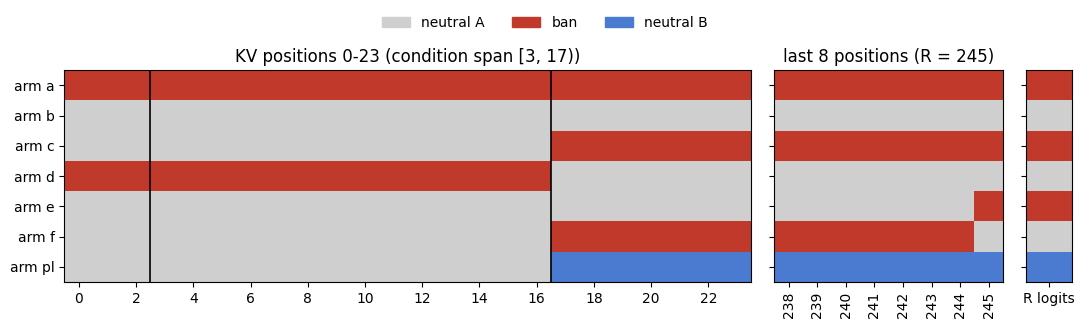

In [9]:
# demo: toy prefill records with the real prompt geometry of T1 / W1; every K/V entry holds its source prompt's id
SRC = {"A": 0.0, "ban": 1.0, "B": 2.0}
SRC_NAME = {0.0: "neutral A", 1.0: "ban", 2.0: "neutral B"}
tw1 = fp["tasks"]["t1"]["templates"]["W1"]
Pw, p0w, p1w = tw1["ban"]["P"], tw1["ban"]["p0"], tw1["ban"]["p1"]


def toy_prefill(src_id: float, P: int, n_layers: int = 2) -> dict[str, Any]:
    """Stand-in for engine.prefill(): per-layer (K, V) of shape [1, 1, P, 1] filled with the source id."""
    kv = [(torch.full((1, 1, P, 1), src_id), torch.full((1, 1, P, 1), src_id)) for _ in range(n_layers)]
    return {"kv": kv, "r_logits": torch.full((4,), src_id), "P": P}


pre = {k: toy_prefill(v, Pw) for k, v in SRC.items()}
arm_src = {}
for name in ("a", "b", "c", "d", "e", "f", "pl"):
    arm = build_arm(name, pre, "A", p1w)          # noun A, as for the half-1 programs
    row = arm["kv"][0][0][0, 0, :, 0]
    assert all(torch.equal(K[0, 0, :, 0], row) and torch.equal(V[0, 0, :, 0], row) for K, V in arm["kv"])
    arm_src[name] = (row.numpy(), float(arm["r_logits"][0]))


def runs(row: np.ndarray) -> list[tuple[int, int, float]]:
    """Compress a per-position source row into (start, end, source) runs."""
    out, s = [], 0
    for i in range(1, len(row) + 1):
        if i == len(row) or row[i] != row[s]:
            out.append((s, i, float(row[s])))
            s = i
    return out


print(f"T1 / W1: P = {Pw} prompt tokens; chat prefix [0, {p0w}), condition span [{p0w}, {p1w}), "
      f"task spec [{p1w}, {Pw - 1}), R = {Pw - 1}\n")
for name, (row, r) in arm_src.items():
    print(f"arm {name:>2}: " + ", ".join(f"[{a}, {b}) {SRC_NAME[v]}" for a, b, v in runs(row))
          + f"  | R logits from {SRC_NAME[r]}")

names = list(arm_src)
M = np.stack([arm_src[n][0] for n in names])
R = np.array([[arm_src[n][1]] for n in names])
cmap3 = ListedColormap(["#cfcfcf", "#c0392b", "#4a7bd0"])
fig, axs = plt.subplots(1, 3, figsize=(11, 3.0), sharey=True, gridspec_kw={"width_ratios": [24, 8, 1.6]})
axs[0].imshow(M[:, :24], cmap=cmap3, vmin=0, vmax=2, aspect="auto", interpolation="nearest")
for xline in (p0w, p1w):
    axs[0].axvline(xline - 0.5, color="k", lw=1.2)
axs[0].set_xticks(range(0, 24, 2))
axs[0].set_title(f"KV positions 0-23 (condition span [{p0w}, {p1w}))")
axs[1].imshow(M[:, Pw - 8:], cmap=cmap3, vmin=0, vmax=2, aspect="auto", interpolation="nearest")
axs[1].set_xticks(range(8))
axs[1].set_xticklabels(range(Pw - 8, Pw), rotation=90)
axs[1].set_title(f"last 8 positions (R = {Pw - 1})")
axs[2].imshow(R, cmap=cmap3, vmin=0, vmax=2, aspect="auto")
axs[2].set_xticks([0])
axs[2].set_xticklabels(["R logits"])
axs[0].set_yticks(range(len(names)))
axs[0].set_yticklabels([f"arm {n}" for n in names])
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap3.colors, ("neutral A", "ban", "neutral B"))],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.1))
fig.tight_layout()
plt.show()

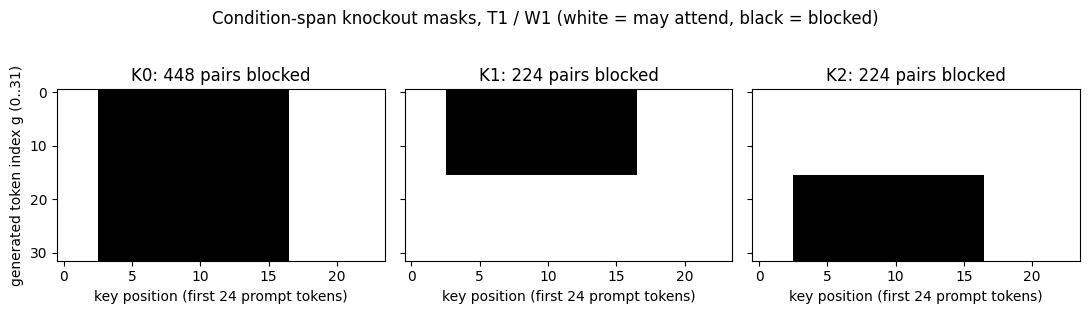

K0: blocks key columns [3, 17) for generated g in [0, end) in layers 0-35 (36 of 36)
K1: blocks key columns [3, 17) for generated g in [0, 16) in layers 0-35 (36 of 36)
K2: blocks key columns [3, 17) for generated g in [16, end) in layers 0-35 (36 of 36)
B1: blocks key columns [3, 17) for generated g in [0, end) in layers 0-11 (12 of 36)
B2: blocks key columns [3, 17) for generated g in [0, end) in layers 12-23 (12 of 36)
B3: blocks key columns [3, 17) for generated g in [0, end) in layers 24-35 (12 of 36)
arms a, b, c, d, e, f, pl: ko_config -> None (stock attention)


In [10]:
# demo: the knockout masks exactly as ko_sdpa builds them during teacher forcing: query rows are the generated
# positions P .. P+T-1 (generated index g = 0 .. T-1), key columns are all cached positions (prompt + generated)
T_gen = KO_DEMO_GEN_TOKENS
k_len = Pw + T_gen
fig, axs = plt.subplots(1, 3, figsize=(11, 3.0), sharey=True)
for ax, name in zip(axs, ("K0", "K1", "K2")):
    with knockout({**ko_config(name, p0w, p1w), "P": Pw}):
        allowed = _combine(_ko_allowed(T_gen, k_len, torch.device("cpu")), None, k_len)[0, 0]   # [T, P + T] bool
    n_blocked = int((~allowed[:, :Pw]).sum())
    ax.imshow(allowed[:, :24].numpy(), cmap="Greys_r", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_title(f"{name}: {n_blocked} pairs blocked")
    ax.set_xlabel("key position (first 24 prompt tokens)")
axs[0].set_ylabel(f"generated token index g (0..{T_gen - 1})")
fig.suptitle("Condition-span knockout masks, T1 / W1 (white = may attend, black = blocked)", y=1.03)
fig.tight_layout()
plt.show()

# which layers each knockout arm touches (_ko_on is checked per attention module via module.layer_idx)
for name in ("K0", "K1", "K2", "B1", "B2", "B3"):
    cfg_ko = ko_config(name, p0w, p1w)
    with knockout({**cfg_ko, "P": Pw}):
        on = [l for l in range(N_LAYERS) if _ko_on(SimpleNamespace(layer_idx=l))]
    g_hi = "end" if cfg_ko["g_hi"] >= 10 ** 9 else cfg_ko["g_hi"]
    print(f"{name}: blocks key columns [{cfg_ko['p0']}, {cfg_ko['p1']}) for generated g in [{cfg_ko['g_lo']}, {g_hi}) "
          f"in layers {on[0]}-{on[-1]} ({len(on)} of {N_LAYERS})")
print("arms a, b, c, d, e, f, pl: ko_config ->", ko_config("a", p0w, p1w), "(stock attention)")

## Stage s8: the pre-registered analysis (`analysis.py`)

This is the code whose sha256 was committed in `results/prereg.json` before any arm was scored or sampled. The cells below copy it unchanged, apart from where its inputs come from.

**The readout.** For an algorithm $j$, a prompt cache $c$ and the 30 self-written programs $p_m$ of $j$:

$$L_j(c) = \log \frac{1}{M}\sum_{m} \exp\big(l(p_m\mid c) - l(p_m\mid F_j)\big)$$

This is an importance-sampling estimate of how likely the model is to write programs like these under $c$. The proposal is the forced-prompt distribution $F_j$ ("Implement {j} for this task.", ...). The FRLP drop of the banned algorithm X is $D_X(\text{arm}) = L_X(\text{arm}) - L_X(b)$, in nats.

The helpers come first: log-mean-exp (`lme`), the importance-weight effective sample size (`ess_of`), percentile CIs and a NaN-safe ratio.

In [11]:
# ------------------------------------------------------------------------------------------------ analysis.py
ARMS_X = ("a", "b", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention")
RNG_SEED = 20261020


# ================================================================================================ helpers
def lme(x: np.ndarray, axis: int = -1) -> np.ndarray:
    """log-mean-exp along axis (NaN-free inputs)."""
    m = np.max(x, axis=axis, keepdims=True)
    return np.squeeze(m, axis) + np.log(np.mean(np.exp(x - m), axis=axis))


def ess_of(lw: np.ndarray, axis: int = -1) -> np.ndarray:
    m = np.max(lw, axis=axis, keepdims=True)
    w = np.exp(lw - m)
    return np.sum(w, axis=axis) ** 2 / np.sum(w ** 2, axis=axis)


def pct(x: np.ndarray, q: float) -> float:
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return float(np.percentile(x, q)) if len(x) else float("nan")


def ci(x: np.ndarray) -> list[float]:
    return [pct(x, 2.5), pct(x, 97.5)]


def safe_ratio(a: Any, b: Any) -> Any:
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(np.abs(b) > 1e-12, a / b, np.nan)

### FRLP tables from the scored programs

For each task and algorithm, `load_frlp` builds three things:

- **The program order**: sorted by half, then by index.
- **Each program's denominator** $l(p\mid F_j) = \log\sum_k \pi_k \exp l(p\mid F_j^k)$: its log-likelihood under the mixture of the forced prompts that generated the programs. $\pi_k$ is the share of generated samples drawn from forced prompt $k$; here it is uniform, 8 samples from each of 10 paraphrases.
- **A lookup table** of every scored log-likelihood.

`lw_tensor` then returns the importance log-weights $lw[\text{cond}, \text{template}, \text{program}] = l(p\mid \text{arm}) - l(p\mid F_j)$, so that $L_j(c) = \log \operatorname{mean}_m \exp lw$.

Each program is scored under the neutral noun of its own half: half 1 uses noun A ("man"), half 2 uses noun B ("guy"). Swapping the nouns gives the placebo comparison.

*Demo change:* the three inputs come from `data` instead of `data/frlp_programs.jsonl`, `results/frlp_programs_summary.json` and `data/frlp_scores.jsonl`. `N_PROGRAMS_DEMO` trims the programs per algorithm the way `frlp.plan_cells(limit=...)` does.

In [12]:
# ================================================================================================ FRLP tables
def load_frlp() -> dict[str, Any]:
    """Returns per task: program order, per-program denominators, and lw arrays per (condition, template)."""
    # demo: the three inputs come from `data` (mini_demo_data.json) instead of data/frlp_programs.jsonl,
    # results/frlp_programs_summary.json and data/frlp_scores.jsonl (each program carries its own score rows);
    # N_PROGRAMS_DEMO keeps prog_index < N per algorithm, like frlp.plan_cells(limit=N)
    progs = [{k: v for k, v in p.items() if k != "scores"} for p in data["examples"]
             if p["prog_index"] < N_PROGRAMS_DEMO]
    summ = data["frlp_programs_summary"]["per_algorithm"]
    scores = [{**r, "uid": p["uid"]} for p in data["examples"] for r in p["scores"]]
    ll: dict[tuple[str, str, str, str], float] = {}
    for r in scores:
        ll[(r["condition"], r["template"], r["noun"], r["uid"])] = r["ll"]
    out: dict[str, Any] = {}
    for t in TASKS:
        tp = [p for p in progs if p["task"] == t]
        for p in tp:
            p["uid"] = f"{p['task']}:{p['algorithm']}:{p['prog_index']}"
        per_alg: dict[str, Any] = {}
        for j in ALGOS[t]:
            pj = sorted([p for p in tp if p["algorithm"] == j], key=lambda p: (p["half"], p["prog_index"]))
            if not pj:
                continue
            counts = summ[f"{t}:{j}"]["prompt_counts"]
            keys, wts = [], []
            for k, n in counts.items():
                kind, idx = k.split(":")
                keys.append(f"forced_{j}_{'p' if kind == 'paraphrase' else 'd'}{idx}")
                wts.append(n)
            wts_a = np.array(wts, dtype=float) / np.sum(wts)
            den, den_gen, ok = [], [], []
            for p in pj:
                vals = [ll.get((kk, "F", "-", p["uid"])) for kk in keys]
                if any(v is None for v in vals):
                    den.append(np.nan)
                    ok.append(False)
                else:
                    v = np.array(vals)
                    m = v.max()
                    den.append(m + math.log(np.sum(wts_a * np.exp(v - m))))
                    ok.append(True)
                gk = f"forced_{j}_{'p' if p['prompt_kind'] == 'paraphrase' else 'd'}{p['prompt_index']}"
                den_gen.append(ll.get((gk, "F", "-", p["uid"]), np.nan))
            per_alg[j] = {"uids": [p["uid"] for p in pj], "half": np.array([p["half"] for p in pj]),
                          "passed": np.array([bool(p["passed"]) for p in pj]), "den": np.array(den),
                          "den_gen": np.array(den_gen), "den_ok": all(ok), "n": len(pj)}
        out[t] = {"alg": per_alg, "ll": ll}
    return out


def _arm_ll(ll: dict, cond: str, w: str, uid: str, half: int) -> float:
    """l(p | arm) for program uid in template w, using the noun of the program's own half."""
    noun = "A" if half == 1 else "B"
    if cond in ("a", "K0", "K1", "K2", "B1", "B2", "B3", "mention"):
        return ll.get((cond, w, "-", uid), np.nan)
    if cond == "pl":
        return ll.get(("pl", w, "AB", uid), np.nan)
    if cond == "bB":  # neutral noun B for every program (placebo reference)
        return ll.get(("b", w, "B", uid), np.nan)
    return ll.get((cond, w, noun, uid), np.nan)


def lw_tensor(F: dict[str, Any], t: str, j: str, conds: tuple[str, ...], den_key: str = "den") -> np.ndarray:
    """lw[cond, template, program] for algorithm j."""
    A = F[t]["alg"][j]
    ll = F[t]["ll"]
    arr = np.full((len(conds), len(TEMPLATE_IDS), A["n"]), np.nan)
    for ci_, c in enumerate(conds):
        for wi, w in enumerate(TEMPLATE_IDS):
            for m, (uid, h) in enumerate(zip(A["uids"], A["half"])):
                arr[ci_, wi, m] = _arm_ll(ll, c, w, uid, int(h)) - A[den_key][m]
    return arr


# demo: a first look at the tables, L_X(arm) per template for the four main arms
F = load_frlp()
for t in TASKS:
    A = F[t]["alg"][X_KEY[t]]
    lw = lw_tensor(F, t, X_KEY[t], MAIN_ARMS)
    print(f"{t} / {X_KEY[t]}: {A['n']} programs (halves {dict(Counter(A['half'].tolist()))}), denominators complete: "
          f"{A['den_ok']}, lw[cond, template, program] shape {lw.shape}")
    print("   L_X(arm) per template W1-W5 (nats):")
    for c, row in zip(MAIN_ARMS, lme(lw, axis=-1)):
        print(f"     arm {c}: " + "  ".join(f"{v:8.2f}" for v in row))

t1 / bfs: 30 programs (halves {1: 15, 2: 15}), denominators complete: True, lw[cond, template, program] shape (4, 5, 30)
   L_X(arm) per template W1-W5 (nats):
     arm a:   -13.56    -20.29    -12.02     -3.68    -23.08
     arm b:    -0.57      0.33     -0.83     -0.33     -1.22
     arm c:   -11.26    -11.19    -10.65     -9.86    -12.66
     arm d:    -1.38     -0.91     -1.06      0.40     -0.72
t2 / dijkstra: 30 programs (halves {1: 15, 2: 15}), denominators complete: True, lw[cond, template, program] shape (4, 5, 30)
   L_X(arm) per template W1-W5 (nats):
     arm a:    -5.56     -6.29     -8.67     -1.20     -7.21
     arm b:     0.09     -0.12      0.26     -0.36      0.09
     arm c:    -2.39     -6.19     -6.25     -3.11     -5.73
     arm d:    -0.08      0.13      0.70      0.83     -0.52


### The D statistic and the two-level crossed bootstrap

`d_stats` turns `lw[cond, template, program]` into $D(c) = L(c) - L(b)$ per template. It then averages over templates with ESS down-weighting: each template gets weight $\min(1, \mathrm{ESS}/5)$, using the smaller ESS of the arm and the baseline.

The bootstrap (`_boot_indices`) resamples templates, and programs within each half, in one crossed draw. Each replicate therefore gives one D per condition, and ratios like $D(c)/D(a)$ are bootstrapped jointly.

`mean_ll_diff` is the unweighted robustness readout F6: the plain mean of $l(p\mid\text{arm}) - l(p\mid b)$.

In [13]:
def _boot_indices(halves: np.ndarray, n_boot: int, rng: np.random.Generator, n_templates: int) -> tuple:
    h1 = np.where(halves == 1)[0]
    h2 = np.where(halves == 2)[0]
    P = np.concatenate([rng.choice(h1, size=(n_boot, len(h1))), rng.choice(h2, size=(n_boot, len(h2)))], axis=1)
    W = rng.integers(0, n_templates, size=(n_boot, n_templates))
    return P, W


def d_stats(lw: np.ndarray, ref: int, P: np.ndarray | None = None, W: np.ndarray | None = None,
            ess_weight: bool = True) -> np.ndarray:
    """lw [C, W, M] -> D[C] (or [B, C] with bootstrap indices): template-averaged L(c) - L(ref), ESS-down-weighted."""
    if P is None:
        L = lme(lw, axis=-1)                     # [C, W]
        E = ess_of(lw, axis=-1)
        D = L - L[ref][None]
        if ess_weight:
            om = np.minimum(1.0, np.minimum(E, E[ref][None]) / THRESHOLDS["ess_flag"])
        else:
            om = np.ones_like(D)
        return np.nansum(om * D, axis=-1) / np.nansum(om, axis=-1)
    # bootstrap: lw[:, W[b], :][:, :, P[b]]
    sub = lw[:, W, :]                             # [C, B, W, M]
    sub = np.take_along_axis(sub, P[None, :, None, :].repeat(sub.shape[2], axis=2), axis=3)
    L = lme(sub, axis=-1)                         # [C, B, W]
    E = ess_of(sub, axis=-1)
    D = L - L[ref][None]
    if ess_weight:
        om = np.minimum(1.0, np.minimum(E, E[ref][None]) / THRESHOLDS["ess_flag"])
    else:
        om = np.ones_like(D)
    return (np.nansum(om * D, axis=-1) / np.nansum(om, axis=-1)).T   # [B, C]


def mean_ll_diff(llx: np.ndarray, ref: int, P: np.ndarray | None = None, W: np.ndarray | None = None) -> np.ndarray:
    """F6 robustness readout without weights: mean over programs and templates of l(p|arm) - l(p|ref)."""
    diff = llx - llx[ref][None]
    if P is None:
        return np.nanmean(diff, axis=(1, 2))
    sub = diff[:, W, :]
    sub = np.take_along_axis(sub, P[None, :, None, :].repeat(sub.shape[2], axis=2), axis=3)
    return np.nanmean(sub, axis=(2, 3)).T

### Route analysis and the frozen decision rule

For each task, `route_analysis` computes D for all 14 conditions with bootstrap CIs, then derives:

- **Route fractions**: $F_\text{direct} = D(d)/D(a)$ and $F_\text{prompt} = D(c)/D(a)$, with interaction $I = D(a) - D(c) - D(d)$. The decomposition arms give $F_R = D(e)/D(a)$ (R only) and $F_\text{spec} = D(f)/D(a)$ (task spec only).
- **Knockout restorations**: $R = (L(K) - L(a)) / (L(b) - L(a))$, both raw and net of the neutral-prompt control K0b. The K1 − K2 contrast gives the veto timing.
- **Placebo splice** $D_{pl}$, which must stay below 20% of $|D(a)|$.
- **Mention-twin split** into a prime part (mention − neutral) and a veto part (ban − mention).
- **Per-template values** and a leave-one-template-out jackknife.
- **Pooled values** over tasks, computed as ratios of sums.

`decide` is the rule committed before scoring:

1. **CONFIRMED_direct_route** if $F_\text{direct} \ge 2/3$ and its 2.5% bootstrap quantile is above 0.5;
2. otherwise **DECIDED_BEFORE_WRITING_prompt_route** if $F_\text{prompt} \ge 2/3$;
3. otherwise **MIXED**.

The result is **ROBUST** when both tasks give the same branch. The `variant` argument selects the four pre-declared sensitivities.

In [14]:
def route_analysis(F: dict[str, Any], n_boot: int = N_BOOT, variant: str = "primary") -> dict[str, Any]:
    """variant: primary | correct_only | gen_paraphrase | no_ess_weight | mean_ll."""
    conds = ("a", "b", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention")
    rng = np.random.default_rng(RNG_SEED)
    res: dict[str, Any] = {"variant": variant, "per_task": {}}
    boots: dict[str, np.ndarray] = {}
    for t in TASKS:
        x = X_KEY[t]
        if x not in F[t]["alg"]:
            continue
        A = F[t]["alg"][x]
        den_key = "den_gen" if variant == "gen_paraphrase" else "den"
        lw = lw_tensor(F, t, x, conds, den_key)
        keep = np.ones(A["n"], dtype=bool)
        if variant == "correct_only":
            keep = A["passed"].copy()
            if not (keep & (A["half"] == 1)).any() or not (keep & (A["half"] == 2)).any():
                continue
        lw = lw[:, :, keep]
        halves = A["half"][keep]
        # templates where a condition is missing entirely are dropped for that condition (NaN-safe means)
        P, W = _boot_indices(halves, n_boot, rng, len(TEMPLATE_IDS))
        ref = conds.index("b")
        if variant == "mean_ll":
            llx = lw + A[den_key][keep][None, None, :]
            point = mean_ll_diff(llx, ref)
            bs = mean_ll_diff(llx, ref, P, W)
        else:
            ew = variant != "no_ess_weight"
            point = d_stats(np.nan_to_num(lw, nan=-1e9), ref, ess_weight=ew)
            bs = d_stats(np.nan_to_num(lw, nan=-1e9), ref, P, W, ess_weight=ew)
        avail = {c: bool(np.isfinite(lw[i]).all()) for i, c in enumerate(conds)}
        point = np.where([avail[c] for c in conds], point, np.nan)
        bs = np.where(np.array([avail[c] for c in conds])[None], bs, np.nan)
        D = {c: float(point[i]) for i, c in enumerate(conds)}
        Db = {c: bs[:, i] for i, c in enumerate(conds)}
        boots[t] = bs
        a_ci = ci(Db["a"])
        ent = {"D": D, "D_ci": {c: ci(Db[c]) for c in conds}, "n_programs": int(keep.sum()),
               "prerequisite_met": bool(D["a"] < 0 and a_ci[1] < 0),
               "F_direct": float(safe_ratio(D["d"], D["a"])), "F_prompt": float(safe_ratio(D["c"], D["a"])),
               "F_direct_ci": ci(safe_ratio(Db["d"], Db["a"])), "F_prompt_ci": ci(safe_ratio(Db["c"], Db["a"])),
               "I": D["a"] - D["c"] - D["d"], "I_ci": ci(Db["a"] - Db["c"] - Db["d"]),
               "F_R": float(safe_ratio(D["e"], D["a"])), "F_R_ci": ci(safe_ratio(Db["e"], Db["a"])),
               "F_spec": float(safe_ratio(D["f"], D["a"])), "F_spec_ci": ci(safe_ratio(Db["f"], Db["a"])),
               "F_direct_p2_5": pct(safe_ratio(Db["d"], Db["a"]), 2.5),
               "F_prompt_p2_5": pct(safe_ratio(Db["c"], Db["a"]), 2.5)}
        # knockout restoration: (L(K on a) - L(a)) / (L(b) - L(a)); D(K) - D(a) = L(K) - L(a) since both minus L(b)
        gap = -D["a"]
        gap_b = -Db["a"]
        ctrl = D["K0b"]
        ctrl_b = Db["K0b"]
        ko = {}
        for k in ("K0", "K1", "K2", "B1", "B2", "B3"):
            raw = safe_ratio(D[k] - D["a"], gap)
            rawb = safe_ratio(Db[k] - Db["a"], gap_b)
            net = safe_ratio(D[k] - D["a"] - ctrl, gap)
            netb = safe_ratio(Db[k] - Db["a"] - ctrl_b, gap_b)
            ko[k] = {"R_raw": float(raw), "R_raw_ci": ci(rawb), "R_net": float(net), "R_net_ci": ci(netb)}
        dk = safe_ratio(Db["K1"] - Db["K2"], gap_b)
        ko["K1_minus_K2"] = {"value": float(safe_ratio(D["K1"] - D["K2"], gap)), "ci": ci(dk)}
        lo, hi = ci(dk)
        ko["veto_timing"] = ("early" if lo > 0 else "late" if hi < 0 else "undetermined")
        ko["generic_damage_K0b"] = {"delta_L": ctrl, "ci": ci(ctrl_b),
                                    "smaller_than_ban_effect": bool(abs(ctrl) < abs(D["a"]))}
        ko["full_knockout_vs_prompt_route"] = {"R_K0_raw": ko["K0"]["R_raw"],
                                               "one_minus_F_prompt": 1 - ent["F_prompt"]}
        ent["knockouts"] = ko
        # placebo: L(pl) - L(b with noun B) over all X programs
        llx = F[t]["ll"]
        pl, bB = [], []
        for wi, w in enumerate(TEMPLATE_IDS):
            v1 = np.array([_arm_ll(llx, "pl", w, u, h) for u, h in zip(A["uids"], A["half"])])[keep] - \
                A[den_key][keep]
            v2 = np.array([_arm_ll(llx, "bB", w, u, h) for u, h in zip(A["uids"], A["half"])])[keep] - \
                A[den_key][keep]
            if np.isfinite(v1).all() and np.isfinite(v2).all():
                pl.append(lme(v1))
                bB.append(lme(v2))
        if pl:
            dpl = float(np.mean(np.array(pl) - np.array(bB)))
            ent["placebo"] = {"D_pl": dpl, "frac_of_D_a": float(abs(dpl) / max(abs(D["a"]), 1e-12)),
                              "passes": bool(abs(dpl) < THRESHOLDS["placebo_max_frac"] * abs(D["a"]))}
        # mention-twin decomposition: prime = mention - neutral, veto = ban - mention
        ent["mention"] = {"prime": D["mention"], "veto": D["a"] - D["mention"],
                          "prime_ci": ci(Db["mention"]), "veto_ci": ci(Db["a"] - Db["mention"])}
        # per-template breakdown and jackknife
        if variant == "primary":
            per_w = {}
            Lw = lme(np.nan_to_num(lw, nan=-1e9), axis=-1)
            Ew = ess_of(np.nan_to_num(lw, nan=-1e9), axis=-1)
            for wi, w in enumerate(TEMPLATE_IDS):
                dd = {c: float(Lw[i, wi] - Lw[ref, wi]) if avail[c] else None for i, c in enumerate(conds)}
                per_w[w] = {"D": dd, "ESS": {c: float(Ew[i, wi]) for i, c in enumerate(conds)},
                            "F_direct": float(safe_ratio(dd["d"], dd["a"])) if dd["a"] else None,
                            "F_prompt": float(safe_ratio(dd["c"], dd["a"])) if dd["a"] else None}
            ent["per_template"] = per_w
            jk = []
            for wi in range(len(TEMPLATE_IDS)):
                mask = [i for i in range(len(TEMPLATE_IDS)) if i != wi]
                pj = d_stats(np.nan_to_num(lw[:, mask], nan=-1e9), ref)
                jk.append({"left_out": TEMPLATE_IDS[wi], "F_direct": float(safe_ratio(pj[conds.index('d')],
                                                                                         pj[0])),
                           "F_prompt": float(safe_ratio(pj[conds.index('c')], pj[0]))})
            ent["template_jackknife"] = jk
            ent["branch"] = decide(ent["F_direct"], ent["F_direct_p2_5"], ent["F_prompt"], ent["F_prompt_p2_5"])
        res["per_task"][t] = ent
    # pooled (ratio of sums over tasks meeting the prerequisite)
    ok = [t for t in res["per_task"] if res["per_task"][t]["prerequisite_met"]]
    res["tasks_in_pool"] = ok
    if ok:
        def pooled(c: str) -> tuple[float, np.ndarray]:
            i = conds.index(c)
            return (sum(res["per_task"][t]["D"][c] for t in ok), sum(boots[t][:, i] for t in ok))

        Da, Dab = pooled("a")
        Dc, Dcb = pooled("c")
        Dd, Ddb = pooled("d")
        res["pooled"] = {
            "D_a": Da, "D_c": Dc, "D_d": Dd,
            "F_direct": float(safe_ratio(Dd, Da)), "F_direct_ci": ci(safe_ratio(Ddb, Dab)),
            "F_direct_p2_5": pct(safe_ratio(Ddb, Dab), 2.5),
            "F_prompt": float(safe_ratio(Dc, Da)), "F_prompt_ci": ci(safe_ratio(Dcb, Dab)),
            "F_prompt_p2_5": pct(safe_ratio(Dcb, Dab), 2.5),
            "I": Da - Dc - Dd, "I_ci": ci(Dab - Dcb - Ddb)}
        pr = res["pooled"]
        pr["branch"] = decide(pr["F_direct"], pr["F_direct_p2_5"], pr["F_prompt"], pr["F_prompt_p2_5"])
        branches = [res["per_task"][t]["branch"]["branch"] for t in ok if res["per_task"][t].get("branch")]
        pr["robust"] = bool(len(ok) == len(TASKS) and len(set(branches)) == 1)
    return res


def decide(f_direct: float, f_direct_lo: float, f_prompt: float, f_prompt_lo: float) -> dict[str, Any]:
    thr, lo = THRESHOLDS["F_confirm"], THRESHOLDS["F_ci_lower"]
    if np.isfinite(f_direct) and f_direct >= thr and f_direct_lo > lo:
        b = "CONFIRMED_direct_route"
    elif np.isfinite(f_prompt) and f_prompt >= thr:
        b = "DECIDED_BEFORE_WRITING_prompt_route"
    else:
        b = "MIXED"
    return {"branch": b, "F_prompt_lower_gt_half": bool(np.isfinite(f_prompt_lo) and f_prompt_lo > lo)}

### Per-cell FRLP rows and per-program shifts

`frlp_cells` writes one row per (task, condition, template, half) with $L$ and its importance-weight ESS. Cells with ESS < 5 are flagged.

T1 arm a has only about 1-3 effective programs out of 30. With weights that degenerate, the likelihood readouts measure how strongly the typical banned-algorithm program, which starts with an import line, is vetoed. They are not calibrated probability ratios.

`program_shift_distributions` (from `supplementary.py`; descriptive, not part of the decision) summarizes the raw per-program shift $\Delta l(p, \text{arm}) = l(p\mid\text{arm}) - l(p\mid b)$ over programs and templates.

In [15]:
def frlp_cells(F: dict[str, Any]) -> list[dict[str, Any]]:
    """Per-cell FRLP rows {task, model, condition, template, algorithm, L, ess, n_programs, half}."""
    rows = []
    for t in TASKS:
        for j, A in F[t]["alg"].items():
            conds = ("a", "b", "c", "d", "mention") if j != X_KEY[t] else ARMS_X
            lw = lw_tensor(F, t, j, conds)
            for ci_, c in enumerate(conds):
                for wi, w in enumerate(TEMPLATE_IDS):
                    for half in (1, 2, "all"):
                        sel = np.ones(A["n"], bool) if half == "all" else (A["half"] == half)
                        v = lw[ci_, wi, sel]
                        if len(v) == 0 or not np.isfinite(v).all():
                            continue
                        e = float(ess_of(v))
                        rows.append({"task": t, "model": "Qwen/Qwen3-8B", "condition": c, "template": w,
                                     "algorithm": j, "L": float(lme(v)), "ess": e, "ess_flag": e < THRESHOLDS["ess_flag"],
                                     "n_programs": int(sel.sum()), "half": str(half)})
    return rows


# ------------------------------------------------------------------------------------------------ supplementary.py
ARMS = ("a", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention")


def program_shift_distributions(F: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        x = X_KEY[t]
        A = F[t]["alg"][x]
        conds = ("b",) + ARMS
        lw = lw_tensor(F, t, x, conds)
        llx = lw + A["den"][None, None, :]
        ent = {}
        for i, c in enumerate(conds[1:], start=1):
            d = llx[i] - llx[0]               # [W, M]
            if not np.isfinite(d).all():
                continue
            flat = d.ravel()
            top_share = []
            for wi in range(len(TEMPLATE_IDS)):
                v = lw[i, wi]
                w = np.exp(v - v.max())
                top_share.append(float(w.max() / w.sum()))
            ent[c] = {"median": float(np.median(flat)), "q25": float(np.percentile(flat, 25)),
                      "q75": float(np.percentile(flat, 75)), "mean": float(flat.mean()),
                      "share_negative": float(np.mean(flat < 0)),
                      "per_template_median": {w: float(np.median(d[wi])) for wi, w in enumerate(TEMPLATE_IDS)},
                      "per_program_mean_over_templates": d.mean(0).tolist(),
                      "top_program_weight_share_per_template": top_share}
        out[t] = ent
    return out

### U9: synthetic checks of the estimators and the C5 test

Before any real arm was scored, the `tests` stage ran `synthetic_checks` on planted data, with three requirements:

1. A ban effect of -2 nats with a direct-route share of 0.8 must be recovered by `d_stats` and its bootstrap.
2. `c5_test` must detect a planted correlation of -0.6. The test combines within-cell Spearman correlations with Fisher-z weights and reports a one-sided stratified permutation p and a bootstrap CI.
3. `c5_test` must reject at most about 10% of shuffled null data sets at alpha = 0.05.

The real C5 test is not part of this demo, because it needs the model's hidden states. It regresses the banned share of 110 ban wordings on the projection of the residual at R onto a leave-one-experiment-out ban direction. The reported result is rho = -0.41 [-0.69, -0.17], p = 0.0003, PARTIAL against the -0.5 bar.

*Demo change:* the hard-coded sizes inside `synthetic_checks` are now the `SYNTH_*` config values.

In [16]:
# ================================================================================================ C5 statistics
def _centred_ranks(v: np.ndarray, axis: int = -1) -> np.ndarray:
    r = stats.rankdata(v, axis=axis)
    return r - r.mean(axis=axis, keepdims=True)


def c5_test(pi: np.ndarray, share: np.ndarray, cells: list[Any], n_perm: int = N_PERM_C5,
            n_boot: int = 2000, seed: int = RNG_SEED + 3) -> dict[str, Any]:
    """Combined within-cell Spearman (Fisher z, weights n-3), one-sided stratified permutation p (H1: rho < 0),
    bootstrap CI resampling wordings within cells. Vectorised: Spearman = Pearson of centred average ranks."""
    rng = np.random.default_rng(seed)
    pi = np.asarray(pi, dtype=float)
    share = np.asarray(share, dtype=float)
    cells = np.asarray(cells)
    groups = [np.where(cells == c)[0] for c in sorted(set(cells.tolist()))]
    ns = [len(g) for g in groups]
    obs_r, perm_r, boot_r = [], [], []
    for g in groups:
        rx, ry = _centred_ranks(pi[g]), _centred_ranks(share[g])
        den = np.linalg.norm(rx) * np.linalg.norm(ry)
        if den == 0 or len(g) < 3:
            obs_r.append(np.nan)
            perm_r.append(np.full(n_perm, np.nan))
            boot_r.append(np.full(n_boot, np.nan))
            continue
        obs_r.append(float(rx @ ry / den))
        perms = np.argsort(rng.random((n_perm, len(g))), axis=1)
        perm_r.append(ry[perms] @ rx / den)
        bi = rng.integers(0, len(g), size=(n_boot, len(g)))
        bx, by = _centred_ranks(pi[g][bi], axis=1), _centred_ranks(share[g][bi], axis=1)
        bden = np.linalg.norm(bx, axis=1) * np.linalg.norm(by, axis=1)
        with np.errstate(invalid="ignore", divide="ignore"):
            boot_r.append(np.where(bden > 0, np.sum(bx * by, axis=1) / bden, np.nan))

    def combine(R: list[np.ndarray]) -> np.ndarray:
        num = np.zeros_like(np.asarray(R[0], dtype=float))
        wsum = np.zeros_like(num)
        for r, n in zip(R, ns):
            r = np.asarray(r, dtype=float)
            ok = np.isfinite(r) & (n > 3)
            num = num + np.where(ok, (n - 3) * np.arctanh(np.clip(np.nan_to_num(r), -0.999999, 0.999999)), 0.0)
            wsum = wsum + np.where(ok, n - 3, 0.0)
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(wsum > 0, np.tanh(num / np.where(wsum > 0, wsum, 1)), np.nan)

    obs = float(combine([np.array(r) for r in obs_r]))
    perm = combine(perm_r)
    boot = combine(boot_r)
    pv = float((1 + np.sum(perm <= obs)) / (1 + n_perm)) if np.isfinite(obs) else float("nan")
    return {"rho": obs, "p_one_sided": pv, "ci": ci(boot), "per_cell_rho": [float(r) for r in obs_r],
            "per_cell_n": ns, "perm_null_mean": float(np.nanmean(perm)), "perm_null_2_5": pct(perm, 2.5)}


# ================================================================================================ U9 synthetic checks
def synthetic_checks() -> dict[str, Any]:
    # demo: the hard-coded sizes 1000 / 2000 / 200 / 200 / 200 are the SYNTH_* configuration values
    rng = np.random.default_rng(7)
    conds = 4  # a, b, c, d
    M, Wn = 30, 5
    base = rng.normal(-5, 1.0, size=(Wn, M))
    lw = np.empty((conds, Wn, M))
    lw[1] = base                      # b
    lw[0] = base - 2.0 + rng.normal(0, 0.3, size=(Wn, M))   # a: ban effect -2
    lw[3] = base - 1.6 + rng.normal(0, 0.3, size=(Wn, M))   # d: 0.8 of the effect
    lw[2] = base - 0.4 + rng.normal(0, 0.3, size=(Wn, M))   # c
    halves = np.array([1, 2] * (M // 2))
    P, W = _boot_indices(halves, SYNTH_N_BOOT, rng, Wn)
    pt = d_stats(lw, 1)
    bs = d_stats(lw, 1, P, W)
    f = float(pt[3] / pt[0])
    fci = ci(bs[:, 3] / bs[:, 0])
    # C5 planted correlation -0.6 and size check
    cells = np.repeat(np.arange(10), 10)
    z = rng.normal(size=100)
    share = np.clip(0.5 - 0.6 * 0.2 * z + rng.normal(0, 0.16, 100), 0, 1)
    planted = c5_test(z, share, cells.tolist(), n_perm=SYNTH_N_PERM, n_boot=SYNTH_C5_N_BOOT)
    rej = 0
    for k in range(SYNTH_N_SIZE_REPS):
        s2 = rng.permutation(share)
        r = c5_test(rng.normal(size=100), s2, cells.tolist(), n_perm=SYNTH_SIZE_N_PERM, n_boot=2, seed=k)
        rej += r["p_one_sided"] < 0.05
    return {"F_direct_true": 0.8, "F_direct_hat": f, "F_direct_ci": fci, "recovered": bool(fci[0] <= 0.8 <= fci[1]),
            "c5_planted_rho": planted["rho"], "c5_planted_p": planted["p_one_sided"],
            "c5_planted_detected": bool(planted["p_one_sided"] < 0.05 and planted["rho"] < 0),
            "c5_size_rejections_of_200": int(rej), "c5_size_ok": bool(rej <= 20 * SYNTH_N_SIZE_REPS / 200)}

## Run the stages the way `method.py` does

`method.py` runs each stage through `_time`, which logs it and appends its runtime to `results/stage_times.jsonl`. Run without arguments, it does `s8 s9`. Here the stage list is the CPU part:

- **`tests`**: the CPU subset of `tests/run_tests.py`, i.e. U2 alignment and U9 synthetic checks, with U2 as the critical gate.
- **`s8`**: `analysis.stage_analysis`, restricted to the FRLP analysis, whose inputs are in the demo data. It runs the primary route analysis, the four sensitivities (correct programs only, generating paraphrase as denominator, no ESS weighting, unweighted mean log-likelihood) and the per-cell rows. It writes `results/analysis.json` and `results/frlp_cells.jsonl`.

In [17]:
# ------------------------------------------------------------------------------------------------ analysis.py (stage)
def stage_analysis() -> dict[str, Any]:
    # demo: the tokenizer import is dropped (only token_localisation needs it)
    out: dict[str, Any] = {}
    F = load_frlp()
    out["route_frlp"] = route_analysis(F)
    out["sensitivities"] = {v: route_analysis(F, n_boot=N_BOOT_SENS, variant=v)
                            for v in ("correct_only", "gen_paraphrase", "no_ess_weight", "mean_ll")}
    # demo: survivor_gains(F) needs the programs of the non-banned algorithms, which the demo data leaves out
    cells = frlp_cells(F)
    write_jsonl(RESULTS_DIR / "frlp_cells.jsonl", cells)  # demo: was DATA_DIR / "frlp_cells.jsonl"
    out["frlp_cells_summary"] = {"n_cells": len(cells),
                                 "n_ess_flagged": sum(c["ess_flag"] for c in cells),
                                 "ess_flagged_by_algorithm": dict(Counter(c["algorithm"] for c in cells
                                                                          if c["ess_flag"]))}
    # demo: behaviour(), coverage(), token_localisation() and the lens / C5 / Holm block read data/samples.jsonl,
    # data/token_lp/*.npz, results/lens.json and results/c5.json, which are not part of the demo data
    write_json(RESULTS_DIR / "analysis.json", out)
    rp = out["route_frlp"]
    logger.info(f"route: pooled={rp.get('pooled')}")
    for t, e in rp["per_task"].items():
        logger.info(f"{t}: D={ {k: round(v, 3) for k, v in e['D'].items() if v == v} } F_direct={e['F_direct']:.3f} "
                    f"F_prompt={e['F_prompt']:.3f} branch={e.get('branch')}")
    return out


# ------------------------------------------------------------------------------------------------ method.py
STAGE_LOG = RESULTS_DIR / "stage_times.jsonl"


def _time(stage: str, fn) -> None:
    t0 = time.time()
    logger.info(f"=== stage {stage} start")
    fn()
    dt = time.time() - t0
    append_jsonl(STAGE_LOG, [{"stage": stage, "seconds": round(dt, 1), "utc": utc_now()}])
    logger.info(f"=== stage {stage} done in {dt / 60:.1f} min")


def tests() -> None:
    # demo: the CPU part of tests.run_tests.run_all() - U2 prompt alignment and U9 synthetic analysis checks
    # (U0 environment and U3-U7 engine / sampler / knockout tests need Qwen3-8B on the GPU)
    res = {"U2": u2_alignment(fp), "U9": synthetic_checks()}
    critical = {
        "U2 alignment": res["U2"]["all_ok"],
    }
    res["critical"] = critical
    write_json(RESULTS_DIR / "tests.json", res)
    bad = [k for k, v in critical.items() if not v]
    if bad:
        raise RuntimeError(f"critical tests failed: {bad}")
    logger.info(f"critical tests passed: {critical}")


def s8() -> None:
    stage_analysis()


# demo: the CPU stages only; s0-s2, s4-s7 and s9 need the GPU, the model or the full data (see the last cell)
STAGES = {"tests": tests, "s8": s8}

setup_logging("method_" + "_".join(STAGES))
t_run = time.time()
for a in STAGES:
    _time(a, STAGES[a])
print(f"\nstages {list(STAGES)} finished in {time.time() - t_run:.1f} s; outputs in {RESULTS_DIR}/")

11:46:59|INFO   |=== stage tests start


11:47:00|INFO   |critical tests passed: {'U2 alignment': True}


11:47:00|INFO   |=== stage tests done in 0.0 min


11:47:00|INFO   |=== stage s8 start


11:47:01|INFO   |route: pooled={'D_a': -18.03100594473, 'D_c': -15.383917881949564, 'D_d': -0.010567848995173157, 'F_direct': 0.0005860931457494121, 'F_direct_ci': [-0.08388340451099108, 0.12283818067882293], 'F_direct_p2_5': -0.08388340451099108, 'F_prompt': 0.8531924358022791, 'F_prompt_ci': [0.6078967260992497, 1.201219276185672], 'F_prompt_p2_5': 0.6078967260992497, 'I': -2.6365202137852637, 'I_ci': [-9.371662687226014, 2.705409322598705], 'branch': {'branch': 'DECIDED_BEFORE_WRITING_prompt_route', 'F_prompt_lower_gt_half': True}, 'robust': True}


11:47:01|INFO   |t1: D={'a': -12.25, 'b': 0.0, 'c': -10.655, 'd': -0.228, 'e': 0.002, 'f': -10.483, 'K0': -11.647, 'K1': -10.736, 'K2': -11.564, 'B1': -13.882, 'B2': -8.29, 'B3': -14.38, 'K0b': -0.213, 'mention': 0.551} F_direct=0.019 F_prompt=0.870 branch={'branch': 'DECIDED_BEFORE_WRITING_prompt_route', 'F_prompt_lower_gt_half': True}


11:47:01|INFO   |t2: D={'a': -5.781, 'b': 0.0, 'c': -4.729, 'd': 0.217, 'e': -0.106, 'f': -4.664, 'K0': -5.422, 'K1': -5.31, 'K2': -5.911, 'B1': -5.884, 'B2': -4.934, 'B3': -5.236, 'K0b': -0.278, 'mention': -0.172} F_direct=-0.038 F_prompt=0.818 branch={'branch': 'DECIDED_BEFORE_WRITING_prompt_route', 'F_prompt_lower_gt_half': True}


11:47:01|INFO   |=== stage s8 done in 0.0 min



stages ['tests', 's8'] finished in 2.3 s; outputs in demo_outputs/results/


## Results: re-derived and reported

Stage s9 (`outputs.stage_outputs`) reads `results/analysis.json` back. The next cell does the same and prints each number next to the one the artifact reported (`data["reported"]`, copied from the full run's `results/analysis.json`).

At the original settings (`N_PROGRAMS_DEMO = 30`, `N_BOOT = 2000`, `N_BOOT_SENS = 500`) the point estimates and the bootstrap intervals agree to floating-point precision, because the same seeds draw the same bootstrap indices. Smaller settings give noisier intervals and can change the branch.

How to read it:

- **D(c) ≈ D(a)**: the ban's task-spec/R states alone reproduce the ban.
- **D(d) ≈ 0**: direct access to the ban sentence from neutral task-spec states does nothing.
- **F_spec ≈ F_prompt, F_R ≈ 0**: the information sits in the task-specification states, not in the read position R alone.
- **ESS**: the low importance-weight ESS of T1 arm a means that T1's likelihood numbers rest on very few effective programs, as the artifact itself states.

In [18]:
an = json.loads((RESULTS_DIR / "analysis.json").read_text())   # as outputs.stage_outputs() reads it back
tres = json.loads((RESULTS_DIR / "tests.json").read_text())
rp = an["route_frlp"]
rep = data["reported"]["route_frlp_primary"]   # the full run's results/analysis.json, for comparison


def fci(v: Any, c: Any) -> str:
    if v is None or c is None or None in c:
        return "n/a"
    return f"{v:7.2f} [{c[0]:6.2f}, {c[1]:6.2f}]"


def f2(v: Any) -> str:
    return "n/a" if v is None else f"{v:.2f}"


arm_order = ["a", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention"]
for t, e in rp["per_task"].items():
    r = rep["per_task"][t]
    print(f"=== {t}: ban {X_KEY[t]} ({e['n_programs']} programs x {len(TEMPLATE_IDS)} templates), "
          f"FRLP drop D_X(arm) in nats")
    print(f"{'':>10}| {'demo [95% CI]':>27} | {'reported [95% CI]':>27}")
    for c in arm_order:
        print(f"{'D(' + c + ')':>10}| {fci(e['D'][c], e['D_ci'][c]):>27} | {fci(r['D'][c], r['D_ci'][c]):>27}")
    for k in ("F_prompt", "F_direct", "I"):
        print(f"{k:>10}| {fci(e[k], e[k + '_ci']):>27} | {fci(r[k], r[k + '_ci']):>27}")
    print(f"   F_R (R only) = {f2(e['F_R'])} (reported {f2(r['F_R'])}); "
          f"F_spec (task spec only) = {f2(e['F_spec'])} (reported {f2(r['F_spec'])})")
    ko = e["knockouts"]
    print("   knockout restoration R_raw, demo (reported): "
          + ", ".join(f"{k} {f2(ko[k]['R_raw'])} ({f2(r['knockouts_R_raw'][k])})"
                      for k in ("K0", "K1", "K2", "B1", "B2", "B3"))
          + f"; K1 vs K2 veto timing: {ko['veto_timing']}")
    pl = e.get("placebo")
    if pl:
        print(f"   placebo splice: D_pl = {pl['D_pl']:.3f} nats = {100 * pl['frac_of_D_a']:.1f}% of |D(a)| "
              f"(rule: < 20%), passes = {pl['passes']}")
    ess_a = [f2(e["per_template"][w]["ESS"]["a"]) for w in TEMPLATE_IDS]
    ess_b = [f2(e["per_template"][w]["ESS"]["b"]) for w in TEMPLATE_IDS]
    print(f"   importance-weight ESS per template (of {e['n_programs']}): arm a {ess_a}, arm b {ess_b}")
    print(f"   branch: {e['branch']['branch']} (reported {r['branch']['branch']})\n")

po, rpo = rp.get("pooled"), rep["pooled"]
if po:
    print("=== pooled over both tasks (ratio of sums)")
    for k in ("F_prompt", "F_direct", "I"):
        print(f"{k:>10}| {fci(po[k], po[k + '_ci']):>27} | {fci(rpo[k], rpo[k + '_ci']):>27}")
    print(f"DECISION: {po['branch']['branch']}, robust across tasks = {po['robust']}   "
          f"(reported: {rpo['branch']['branch']}, robust = {rpo['robust']})")
else:
    print("no pooled values: both tasks must meet the prerequisite D(a) < 0 with CI below 0 (raise the config values)")

print("\n=== the four pre-declared sensitivities: pooled F_prompt / F_direct, demo (reported)")
for v, s in an["sensitivities"].items():
    sp, rs = s.get("pooled"), data["reported"]["sensitivities_pooled"].get(v)
    if sp and rs:
        print(f"{v:>15}: F_prompt {f2(sp['F_prompt'])} ({f2(rs['F_prompt'])}), F_direct {f2(sp['F_direct'])} "
              f"({f2(rs['F_direct'])}) -> {sp['branch']['branch']}")

if po:
    diffs = [abs(rp["per_task"][t]["D"][c] - rep["per_task"][t]["D"][c]) for t in TASKS for c in arm_order]
    diffs += [abs(po[k] - rpo[k]) for k in ("D_a", "D_c", "D_d", "F_prompt", "F_direct")]
    diffs += [abs(a - b) for k in ("F_prompt_ci", "F_direct_ci") for a, b in zip(po[k], rpo[k])]
    print(f"\nmax |demo - reported| over {len(diffs)} point estimates and pooled CI bounds: {max(diffs):.2e}")

cs = an["frlp_cells_summary"]
print(f"\nFRLP cells of the banned-algorithm programs: {cs['n_cells']}, flagged ESS < 5: {cs['n_ess_flagged']} "
      f"{cs['ess_flagged_by_algorithm']}")
u9 = tres["U9"]
print(f"U9 synthetic checks: planted F_direct 0.8 -> {u9['F_direct_hat']:.3f} "
      f"[{u9['F_direct_ci'][0]:.3f}, {u9['F_direct_ci'][1]:.3f}], recovered = {u9['recovered']}; "
      f"planted C5 correlation -> rho = {u9['c5_planted_rho']:.3f}, p = {u9['c5_planted_p']:.4f}, "
      f"detected = {u9['c5_planted_detected']}; C5 size: {u9['c5_size_rejections_of_200']} rejections "
      f"in {SYNTH_N_SIZE_REPS} null data sets, ok = {u9['c5_size_ok']}")

=== t1: ban bfs (30 programs x 5 templates), FRLP drop D_X(arm) in nats
          |               demo [95% CI] |           reported [95% CI]
      D(a)|     -12.25 [-20.89,  -6.90] |     -12.25 [-20.89,  -6.90]
      D(c)|     -10.65 [-12.35,  -9.59] |     -10.65 [-12.35,  -9.59]
      D(d)|      -0.23 [ -2.97,   0.83] |      -0.23 [ -2.97,   0.83]
      D(e)|       0.00 [ -0.37,   0.23] |       0.00 [ -0.37,   0.23]
      D(f)|     -10.48 [-12.48,  -9.25] |     -10.48 [-12.48,  -9.25]
     D(K0)|     -11.65 [-13.57,  -9.94] |     -11.65 [-13.57,  -9.94]
     D(K1)|     -10.74 [-15.54,  -9.45] |     -10.74 [-15.54,  -9.45]
     D(K2)|     -11.56 [-15.70,  -6.83] |     -11.56 [-15.70,  -6.83]
     D(B1)|     -13.88 [-22.29,  -7.71] |     -13.88 [-22.29,  -7.71]
     D(B2)|      -8.29 [-11.38,  -4.21] |      -8.29 [-11.38,  -4.21]
     D(B3)|     -14.38 [-20.15, -11.49] |     -14.38 [-20.15, -11.49]
    D(K0b)|      -0.21 [ -0.63,   0.57] |      -0.21 [ -0.63,   0.57]
D(mention)|       

## Visualization

First comes the artifact's own figure code (`outputs.make_figures`: fig1 and fig3). It is unchanged except that figures render inline instead of being closed.

- **fig1** shows the FRLP drop of the banned algorithm in every arm. The prompt-route arm c sits next to the full ban a. The direct-route arm d sits at zero with the baseline.
- **fig3** shows how much of the ban gap each condition-span knockout restores. Zero means the ban survives the knockout; the dotted line at one means the ban is fully undone.

The last figure summarizes the route decomposition and the per-program shifts behind it.

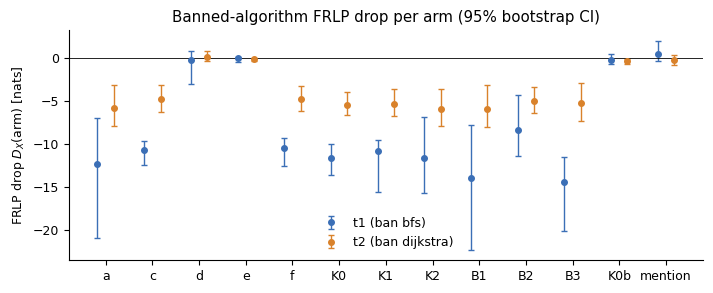

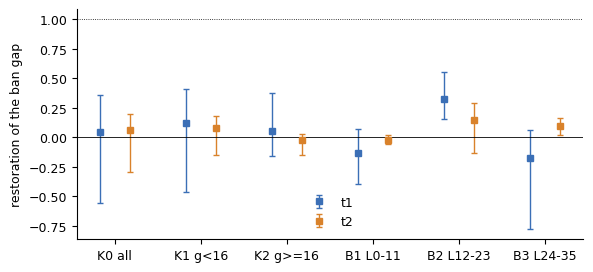

11:47:03|INFO   |figures written


In [19]:
# ------------------------------------------------------------------------------------------------ outputs.py (figures)
def make_figures(an: dict[str, Any]) -> None:
    # demo: matplotlib.use("Agg") is dropped and plt.close(fig) became plt.show(), so the figures render inline;
    # fig2 (token localisation), fig4 (lens), fig5 (C5) and fig6 (behaviour) need data outside the demo set
    plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
    C = {"t1": "#3b6fb6", "t2": "#d9822b", "pooled": "#444444"}
    rp = an["route_frlp"]
    # fig1: D_X per arm with CIs
    arms = ["a", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention"]
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    for k, t in enumerate(TASKS):
        e = rp["per_task"].get(t)
        if not e:
            continue
        xs = np.arange(len(arms)) + (k - 0.5) * 0.35
        ys = [e["D"].get(a, np.nan) for a in arms]
        lo = [e["D_ci"][a][0] if e["D_ci"].get(a) else np.nan for a in arms]
        hi = [e["D_ci"][a][1] if e["D_ci"].get(a) else np.nan for a in arms]
        ys, lo, hi = (np.array(v, dtype=float) for v in (ys, lo, hi))
        ax.errorbar(xs, ys, yerr=[ys - lo, hi - ys], fmt="o", ms=4, color=C[t], label=f"{t} (ban {X_KEY[t]})",
                    capsize=2, lw=1)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(np.arange(len(arms)))
    ax.set_xticklabels(arms)
    ax.set_ylabel("FRLP drop $D_X$(arm) [nats]")
    ax.set_title("Banned-algorithm FRLP drop per arm (95% bootstrap CI)")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig1_frlp_drop_per_arm.png", dpi=200)
    fig.savefig(FIG_DIR / "fig1_frlp_drop_per_arm.pdf")
    plt.show()
    # fig3: knockout restoration
    fig, ax = plt.subplots(figsize=(6.0, 2.8))
    ks = ["K0", "K1", "K2", "B1", "B2", "B3"]
    for k, t in enumerate(TASKS):
        e = rp["per_task"].get(t)
        if not e:
            continue
        ko = e["knockouts"]
        xs = np.arange(len(ks)) + (k - 0.5) * 0.35
        ys = np.array([ko[x]["R_raw"] for x in ks])
        lo = np.array([ko[x]["R_raw_ci"][0] for x in ks])
        hi = np.array([ko[x]["R_raw_ci"][1] for x in ks])
        ax.errorbar(xs, ys, yerr=[ys - lo, hi - ys], fmt="s", ms=4, color=C[t], capsize=2, lw=1, label=t)
    ax.axhline(0, color="k", lw=0.6)
    ax.axhline(1, color="k", lw=0.6, ls=":")
    ax.set_xticks(np.arange(len(ks)))
    ax.set_xticklabels(["K0 all", "K1 g<16", "K2 g>=16", "B1 L0-11", "B2 L12-23", "B3 L24-35"])
    ax.set_ylabel("restoration of the ban gap")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig3_knockout_restoration.png", dpi=200)
    fig.savefig(FIG_DIR / "fig3_knockout_restoration.pdf")
    plt.show()
    logger.info("figures written")


make_figures(an)

t1 median shift (nats), share of program x template pairs below 0: {'a': (-17.41, 0.98), 'c': (-11.58, 1.0), 'd': (-2.57, 0.73), 'e': (0.15, 0.41), 'f': (-11.68, 1.0), 'K0': (-11.78, 1.0), 'K1': (-13.29, 1.0), 'K2': (-14.09, 0.99), 'B1': (-17.88, 0.97), 'B2': (-8.98, 0.92), 'B3': (-17.52, 1.0), 'K0b': (0.25, 0.4), 'mention': (2.92, 0.1)}
t2 median shift (nats), share of program x template pairs below 0: {'a': (-6.48, 0.98), 'c': (-5.03, 1.0), 'd': (0.23, 0.31), 'e': (-0.04, 0.64), 'f': (-5.19, 1.0), 'K0': (-5.81, 1.0), 'K1': (-6.05, 1.0), 'K2': (-6.14, 1.0), 'B1': (-6.92, 0.95), 'B2': (-5.34, 1.0), 'B3': (-5.89, 0.98), 'K0b': (-0.7, 0.83), 'mention': (0.1, 0.45)}


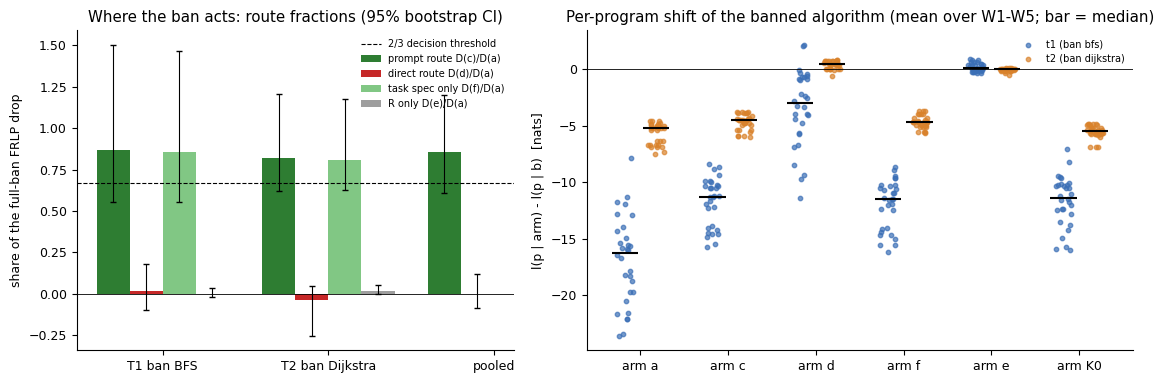

Pooled F_prompt = 0.85 [0.61, 1.20], F_direct = 0.00 [-0.08, 0.12] -> DECIDED_BEFORE_WRITING_prompt_route (robust = True)


In [20]:
# Supplementary per-program shifts (the FRLP part of supplementary.main()) and a one-figure summary of the route test
sup = {"program_shift_distributions": program_shift_distributions(load_frlp())}
for t, e in sup["program_shift_distributions"].items():
    print(t, "median shift (nats), share of program x template pairs below 0:",
          {k: (round(v["median"], 2), round(v["share_negative"], 2)) for k, v in e.items()})


def _f(x: Any) -> float:
    return np.nan if x is None else float(x)


C = {"t1": "#3b6fb6", "t2": "#d9822b", "pooled": "#444444"}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
# (left) route fractions with 95% bootstrap CIs, per task and pooled
groups = [("T1 ban BFS", rp["per_task"].get("t1")), ("T2 ban Dijkstra", rp["per_task"].get("t2")),
          ("pooled", rp.get("pooled"))]
keys = [("F_prompt", "prompt route D(c)/D(a)", "#2e7d32"), ("F_direct", "direct route D(d)/D(a)", "#c62828"),
        ("F_spec", "task spec only D(f)/D(a)", "#81c784"), ("F_R", "R only D(e)/D(a)", "#9e9e9e")]
for gi, (g, e) in enumerate(groups):
    if not e:
        continue
    for ki, (k, lab, col) in enumerate(keys):
        if k not in e:
            continue
        x, v = gi + (ki - 1.5) * 0.2, _f(e[k])
        lo, hi = (_f(c) for c in e.get(k + "_ci", [None, None]))
        axs[0].bar(x, v, width=0.2, color=col, label=lab if gi == 0 else None)
        axs[0].errorbar(x, v, yerr=[[v - lo], [hi - v]], color="k", capsize=2, lw=0.8)
axs[0].axhline(THRESHOLDS["F_confirm"], color="k", ls="--", lw=0.8, label="2/3 decision threshold")
axs[0].axhline(0, color="k", lw=0.6)
axs[0].set_xticks(range(len(groups)))
axs[0].set_xticklabels([g for g, _ in groups])
axs[0].set_ylabel("share of the full-ban FRLP drop")
axs[0].set_title("Where the ban acts: route fractions (95% bootstrap CI)")
axs[0].legend(frameon=False, fontsize=7, loc="best")
# (right) per-program shift of the banned algorithm's log-likelihood, mean over the five templates
arms_s = ["a", "c", "d", "f", "e", "K0"]
rng_j = np.random.default_rng(0)
for k, t in enumerate(TASKS):
    e = sup["program_shift_distributions"].get(t, {})
    for i, a in enumerate(arms_s):
        if a not in e:
            continue
        y = np.array(e[a]["per_program_mean_over_templates"])
        x0 = i + (k - 0.5) * 0.36
        axs[1].scatter(x0 + rng_j.uniform(-0.09, 0.09, len(y)), y, s=10, color=C[t], alpha=0.7,
                       label=f"{t} (ban {X_KEY[t]})" if i == 0 else None)
        axs[1].hlines(np.median(y), x0 - 0.15, x0 + 0.15, color="k", lw=1.5)
axs[1].axhline(0, color="k", lw=0.6)
axs[1].set_xticks(range(len(arms_s)))
axs[1].set_xticklabels([f"arm {a}" for a in arms_s])
axs[1].set_ylabel("l(p | arm) - l(p | b)  [nats]")
axs[1].set_title("Per-program shift of the banned algorithm (mean over W1-W5; bar = median)")
axs[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "demo_route_summary.png", dpi=200)
plt.show()

po = rp.get("pooled")
if po:
    print(f"Pooled F_prompt = {po['F_prompt']:.2f} [{po['F_prompt_ci'][0]:.2f}, {po['F_prompt_ci'][1]:.2f}], "
          f"F_direct = {po['F_direct']:.2f} [{po['F_direct_ci'][0]:.2f}, {po['F_direct_ci'][1]:.2f}] -> "
          f"{po['branch']['branch']} (robust = {po['robust']})")

## What the demo shows, and what it leaves out

- **Reproduced here, on CPU:** the pre-registered C2 decision. The ban's effect on the banned algorithm's programs is carried by the **prompt route**. Splicing in the ban's task-spec and R states (arm c) reproduces about 85% of the full-ban drop. Letting the generated tokens read the ban sentence directly on top of neutral task-spec states (arm d) reproduces about none of it. R alone (arm e) carries nothing, and the task-spec states (arm f) carry almost all of it. Knocking out the condition span for every generated token (K0) restores only about 5% of the gap, and the placebo splice moves about 1% of the effect.
- **Needs the GPU, not run here:**
  - s2: generating the 323 forced programs.
  - s4: behaviour sampling with common random numbers. Banned share for arms a/b/c/d is 0.14/1.00/0.57/0.70 for T1 and 0.11/0.99/0.13/0.95 for T2.
  - s5: the FRLP scoring itself.
  - s6: the logit and tuned lens.
  - s7: the C5 compliance-at-R test (rho = -0.41, PARTIAL).

  Their code is in `engine.py`, `behaviour.py`, `frlp.py`, `lens.py` and `c5.py` in the artifact folder. `reproducibility.md` lists the exact commands (about 70 minutes on one RTX 4090).
- **Mechanism, from the behaviour data:** the ban removes the model's default first line (`from collections import deque` / `import heapq`). Programs open with an import line 0% of the time under arms a, c and every knockout, and 85% of the time under d. The likelihood readouts are dominated by that opening fork. That is why they call T1 a prompt-route case even though its behaviour also shows a direct component.

To run the analysis at a different scale, change the configuration cell. The original values are `N_PROGRAMS_DEMO = 30`, `N_BOOT = 2000` and `N_BOOT_SENS = 500`.